In [ ]:
import os
import sys
import subprocess
import importlib
import calendar
import pickle
import warnings
import json
import joblib
import random as _random
import re as _re
from copy import deepcopy
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import lightgbm as lgb
import torch
import torch.nn as nn
import torch.optim as optim
import networkx as nx

NODE_REPO = next(
    (path for path in [Path.cwd() / 'node_repo', Path.cwd() / 'notebook' / 'working' / 'node_repo'] if path.exists()),
    Path('node_repo'),
)
if str(NODE_REPO) not in sys.path:
    sys.path.insert(0, str(NODE_REPO))
import lib.nn_utils as node_nn_utils
node_nn_utils = importlib.reload(node_nn_utils)
import lib as node_lib
node_lib = importlib.reload(node_lib)

from eventregistry import *
from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from ta.trend import MACD, SMAIndicator
from ta.momentum import RSIIndicator, ROCIndicator
from ta.volatility import BollingerBands
from typing import Optional, List, Tuple, Dict, Any
from dotenv import load_dotenv
from pyvis.network import Network



# Ignore all warnings
warnings.filterwarnings('ignore')

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')



# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "lines.linewidth": 2.5,
})

# Configuration
FORECAST_HORIZONS = [1, 7, 14, 30]
TEST_SIZE_DAYS = 30  # Last 30 days for testing
RANDOM_STATE = 42
LSTM_LOOKBACK = 14
MODEL_DIR = '../../models'

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Create model directory if it doesn't exist
os.makedirs(MODEL_DIR, exist_ok=True)

load_dotenv()

print("✓ Imports complete")

✓ Imports complete


In [2]:
X_train = pd.read_csv('../../data/FinalDataset/X_train.csv', index_col=0)
X_test = pd.read_csv('../../data/FinalDataset/X_test.csv', index_col=0)
y_train = pd.read_csv('../../data/FinalDataset/y_train.csv', index_col=0).squeeze('columns')
y_test = pd.read_csv('../../data/FinalDataset/y_test.csv', index_col=0).squeeze('columns')

X_train_with_date = X_train.copy()
X_test_with_date = X_test.copy()

X_train.drop(columns=["Date", "Station"], inplace=True)
X_test.drop(columns=["Date", "Station"], inplace=True)

In [3]:
X_train

,Production,Factory_Issue,Delivery,Rainfall,Sunshine,Humidity,Temperature,typical_rain_mm,Sales_lag_1,Sales_lag_2,Sales_lag_3,Sales_lag_7,Sales_lag_14,Sales_lag_21,Sales_lag_28,production_sales_ratio,delivery_sales_ratio,factory_issue_rate,inventory_proxy,interest_rate_value,stock_market_close,inflation_rate,balance_of_trade,exports,imports,currency_log_return,currency_momentum_5d,Product_AT5X5K,Product_ATN01K24P,Product_ATN02K12P,Product_ATPA1K24P,Product_ATPPCH5X5K,Product_ATWWP001K24P,Product_ATWWP002K12P,Product_EEA200G24P,Product_EEA500G12P,Product_MAC1K25P,Product_MAHS025K,Product_MAP1K25P,Product_MAPA1K24P,Product_MAR01K24P,Product_MAR02K12P,Product_MASR025K,Product_POP001L12P,Product_POP001L12P.1,Product_POP002L09P,Product_POP005L04P,Product_POP015K,Product_POP500M24P,Product_POPF01L12P,Product_POV001L24P,Product_POV002L09P,Product_POV005L04P,Product_POV500M24P,Product_SE200G24P,Product_SE500G24P,Product_SO0001L12P,Product_SO0002L09P,Product_SO0005L04P,Product_SO0500M24P,Product_SOP001L12P,Product_SOS001L12P,Product_SOS002L09P,Product_SOS003L04P,Product_SOS005L04P,Product_SOS008L02P,Product_SOS250M48P,Product_SOS500M24P,Group_A,Group_E,Group_M,Group_P,Group_S,Group_nan,Sub-Group_AT,Sub-Group_ATN,Sub-Group_ATPA,Sub-Group_ATPPCH,Sub-Group_ATWWP,Sub-Group_EEA,Sub-Group_MAC,Sub-Group_MAHS,Sub-Group_MAP,Sub-Group_MAPA,Sub-Group_MAR,Sub-Group_MASR,Sub-Group_POP,Sub-Group_POPF,Sub-Group_POV,Sub-Group_SE,Sub-Group_SO,Sub-Group_SOP,Sub-Group_SOS,Sub-Group_nan,holiday_type_National Holiday,holiday_type_Not a National Holiday,holiday_type_nan,holiday_name_Ashura,holiday_name_Bank Holiday,holiday_name_Bengali New Year,holiday_name_Buddha Purnima,holiday_name_Eid al-Fitr,holiday_name_Eid-ul-Azha,holiday_name_Independence Day,holiday_name_Jumatul Bidah,holiday_name_Language Mother Day,holiday_name_May Day,holiday_name_Shab e-barat,holiday_name_Shab-e-Qadr,holiday_name_Sheikh Mujibur Rahman's birthday,holiday_name_nan,category_bank_holiday,category_cultural_event,category_cultural_holiday,category_national_holiday,category_no_event,category_religious_holiday,category_religious_period,category_school_university,category_weather_event,scope_or_location_Chattogram division & south-east,scope_or_location_Nationwide,scope_or_location_Nationwide (strongest in Buddhist communities),scope_or_location_Nationwide (strongest in cities),scope_or_location_Tongi near Dhaka,scope_or_location_Urban centres (esp. Dhaka),scope_or_location_nan
0,0.079538,0.049447,0.038181,0.000000,0.380952,0.777778,0.222222,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.567752,2.676003e-01,6.466667e-01,0.621192,0.0,0.000000,0.000000,0.600135,0.823701,0.481245,0.000000,0.000000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,0.079538,0.087679,0.125128,0.000000,0.523810,0.619048,0.280193,0.0,0.090322,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.401869,2.165421e+00,1.146667e+00,0.625206,0.0,0.000000,0.000000,0.600135,0.823701,0.481245,0.000000,0.000000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.106050,0.151093,0.119652,0.000000,0.000000,0.873016,0.140097,0.0,0.036580,0.090322,0.000000,0.000000,0.000000,0.000000,0.000000,0.849257,9.408068e-01,1.482000e+00,0.621892,0.0,0.037881,0.000000,0.600135,0.823701,0.481245,0.127194,0.000000,1.0,0.0,0

In [4]:
X_test

,Production,Factory_Issue,Delivery,Rainfall,Sunshine,Humidity,Temperature,typical_rain_mm,Sales_lag_1,Sales_lag_2,Sales_lag_3,Sales_lag_7,Sales_lag_14,Sales_lag_21,Sales_lag_28,production_sales_ratio,delivery_sales_ratio,factory_issue_rate,inventory_proxy,interest_rate_value,stock_market_close,inflation_rate,balance_of_trade,exports,imports,currency_log_return,currency_momentum_5d,Product_AT5X5K,Product_ATN01K24P,Product_ATN02K12P,Product_ATPA1K24P,Product_ATPPCH5X5K,Product_ATWWP001K24P,Product_ATWWP002K12P,Product_EEA200G24P,Product_EEA500G12P,Product_MAC1K25P,Product_MAHS025K,Product_MAP1K25P,Product_MAPA1K24P,Product_MAR01K24P,Product_MAR02K12P,Product_MASR025K,Product_POP001L12P,Product_POP001L12P.1,Product_POP002L09P,Product_POP005L04P,Product_POP015K,Product_POP500M24P,Product_POPF01L12P,Product_POV001L24P,Product_POV002L09P,Product_POV005L04P,Product_POV500M24P,Product_SE200G24P,Product_SE500G24P,Product_SO0001L12P,Product_SO0002L09P,Product_SO0005L04P,Product_SO0500M24P,Product_SOP001L12P,Product_SOS001L12P,Product_SOS002L09P,Product_SOS003L04P,Product_SOS005L04P,Product_SOS008L02P,Product_SOS250M48P,Product_SOS500M24P,Group_A,Group_E,Group_M,Group_P,Group_S,Group_nan,Sub-Group_AT,Sub-Group_ATN,Sub-Group_ATPA,Sub-Group_ATPPCH,Sub-Group_ATWWP,Sub-Group_EEA,Sub-Group_MAC,Sub-Group_MAHS,Sub-Group_MAP,Sub-Group_MAPA,Sub-Group_MAR,Sub-Group_MASR,Sub-Group_POP,Sub-Group_POPF,Sub-Group_POV,Sub-Group_SE,Sub-Group_SO,Sub-Group_SOP,Sub-Group_SOS,Sub-Group_nan,holiday_type_National Holiday,holiday_type_Not a National Holiday,holiday_type_nan,holiday_name_Ashura,holiday_name_Bank Holiday,holiday_name_Bengali New Year,holiday_name_Buddha Purnima,holiday_name_Eid al-Fitr,holiday_name_Eid-ul-Azha,holiday_name_Independence Day,holiday_name_Jumatul Bidah,holiday_name_Language Mother Day,holiday_name_May Day,holiday_name_Shab e-barat,holiday_name_Shab-e-Qadr,holiday_name_Sheikh Mujibur Rahman's birthday,holiday_name_nan,category_bank_holiday,category_cultural_event,category_cultural_holiday,category_national_holiday,category_no_event,category_religious_holiday,category_religious_period,category_school_university,category_weather_event,scope_or_location_Chattogram division & south-east,scope_or_location_Nationwide,scope_or_location_Nationwide (strongest in Buddhist communities),scope_or_location_Nationwide (strongest in cities),scope_or_location_Tongi near Dhaka,scope_or_location_Urban centres (esp. Dhaka),scope_or_location_nan
191,0.053025,0.074017,0.057634,0.026087,0.000000,0.698413,0.821256,0.000000,0.040648,0.071895,0.002373,0.031725,0.003897,0.023931,0.001197,4.219409e+00,4.502954e+00,1.452000,0.589769,0.0,0.791970,0.817518,0.000000,1.00000,1.00000,0.598798,0.719193,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
192,0.053025,0.037468,0.025328,0.000000,0.009524,0.698413,0.811594,0.000000,0.008102,0.040648,0.071895,0.013777,0.000000,0.024785,0.034358,1.972387e+00,9.250493e-01,0.735000,0.594371,0.0,0.838398,0.817518,0.000000,1.00000,1.00000,0.563015,0.716944,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
193,0.042420,0.015803,0.027650,0.008696,0.371429,0.714286,0.816425,0.000000,0.017333,0.008102,0.040648,0.042665,0.000000,0.034118,0.040648,7.662835e-01,4.904215e-01,0.387500,0.592093,0.0,0.861137,0.817518,0.000000,1.00000,1.00000,0.566266,0.7

In [5]:
y_train

0       0.090322
1       0.036580
2       0.080510
3       0.031103
4       0.119791
          ...   
9026    0.113706
9027    0.000000
9028    0.017538
9029    0.169943
9030    0.112509
Name: Sales, Length: 7831, dtype: float64

In [6]:
y_test

191     0.008102
192     0.017333
193     0.035691
194     0.000000
195     0.001005
          ...   
9056    0.003726
9057    0.099039
9058    0.081536
9059    0.000000
9060    0.000000
Name: Sales, Length: 1230, dtype: float64

<br> <br> <br>

## Defining ML Metrics

In [7]:
def calculate_metrics(y_true, y_pred, model_name="Model", y_train=None):
    """Calculate comprehensive evaluation metrics including MASE"""
    mask = ~(np.isnan(y_true) | np.isnan(y_pred))
    y_true_clean = y_true[mask]
    y_pred_clean = y_pred[mask]
    
    rmse = np.sqrt(mean_squared_error(y_true_clean, y_pred_clean))
    mae = mean_absolute_error(y_true_clean, y_pred_clean)
    r2 = r2_score(y_true_clean, y_pred_clean)
    
    # MAPE calculation
    mask_nonzero = y_true_clean != 0
    if mask_nonzero.sum() > 0:
        mape = np.mean(np.abs((y_true_clean[mask_nonzero] - y_pred_clean[mask_nonzero]) / y_true_clean[mask_nonzero])) * 100
    else:
        mape = np.nan
    
    # MASE calculation
    # MASE = MAE / MAE_naive, where naive forecast is y_{t-1}
    if y_train is not None and len(y_train) > 1:
        # Use training data for scaling factor (preferred method)
        y_train_clean = y_train[~np.isnan(y_train)]
        naive_errors = np.abs(np.diff(y_train_clean))
        scale = np.mean(naive_errors)
    elif len(y_true_clean) > 1:
        # Fallback: use test data for scaling factor
        naive_errors = np.abs(np.diff(y_true_clean))
        scale = np.mean(naive_errors)
    else:
        scale = np.nan
    
    if scale > 0 and not np.isnan(scale):
        mase = mae / scale
    else:
        mase = np.nan
    
    return {
        'Model': model_name,
        'RMSE': rmse,
        'MAE': mae,
        'MAPE': mape,
        'MASE': mase,
        'R²': r2,
        'N_samples': len(y_true_clean)
    }


def print_metrics_summary(metrics_dict):
    """Print metrics in formatted way"""
    print(f"{metrics_dict['Model']:35s} | RMSE: {metrics_dict['RMSE']:>10.6f} | MAE: {metrics_dict['MAE']:>10.6f} | MAPE: {metrics_dict['MAPE']:>6.2f}% | MASE: {metrics_dict['MASE']:>6.3f} | R²: {metrics_dict['R²']:>6.4f}")

print("✓ Helper functions defined")

✓ Helper functions defined


<br> <br> <br>

## Training Machine Learning Models (Macro Economics Included)

In [8]:
# Dictionary to store models and results
models = {}
predictions = {}
metrics_results = []

print("="*80)
print("TRAINING MULTIPLE MODELS")
print("="*80)

TRAINING MULTIPLE MODELS


In [10]:
# 1. Random Forest
print("\n1. Training Random Forest...")
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

models['RandomForest'] = rf_model
predictions['RandomForest'] = rf_pred

rf_metrics = calculate_metrics(y_test, rf_pred, "RandomForest", y_train=y_train)
metrics_results.append(rf_metrics)
print_metrics_summary(rf_metrics)

# # Save RandomForest model
# rf_path = os.path.join(MODEL_DIR, "RandomForest.pkl")
# with open(rf_path, 'wb') as f:
#     pickle.dump(rf_model, f)
# print(f"  ✓ RandomForest saved -> {rf_path}")


1. Training Random Forest...
RandomForest                        | RMSE:        0 | MAE:        0 | MAPE:  51.60% | MASE:  0.167 | R²: 0.9402


In [ ]:
# 2. XGBoost
print("\n2. Training XGBoost...")
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

xgb_model.fit(X_train, y_train, verbose=False)
xgb_pred = xgb_model.predict(X_test)

models['XGBoost'] = xgb_model
predictions['XGBoost'] = xgb_pred

xgb_metrics = calculate_metrics(y_test, xgb_pred, "XGBoost", y_train=y_train)
metrics_results.append(xgb_metrics)
print_metrics_summary(xgb_metrics)

# Save XGBoost model
xgb_path = os.path.join(MODEL_DIR, "XGBoost.pkl")
with open(xgb_path, 'wb') as f:
    pickle.dump(xgb_model, f)
print(f"  ✓ XGBoost saved -> {xgb_path}")

In [ ]:
# 3. LightGBM
print("\n3. Training LightGBM...")
lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(X_train, y_train)
lgb_pred = lgb_model.predict(X_test)

models['LightGBM'] = lgb_model
predictions['LightGBM'] = lgb_pred

lgb_metrics = calculate_metrics(y_test, lgb_pred, "LightGBM", y_train=y_train)
metrics_results.append(lgb_metrics)
print_metrics_summary(lgb_metrics)

# Save LightGBM model
lgb_path = os.path.join(MODEL_DIR, "LightGBM.pkl")
with open(lgb_path, 'wb') as f:
    pickle.dump(lgb_model, f)
print(f"  ✓ LightGBM saved -> {lgb_path}")

In [ ]:
# 4. CatBoost
print("\n4. Training CatBoost...")
cat_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    subsample=0.8,
    colsample_bylevel=0.8,
    random_state=42,
    verbose=False
)

cat_model.fit(X_train, y_train)
cat_pred = cat_model.predict(X_test)

models['CatBoost'] = cat_model
predictions['CatBoost'] = cat_pred

cat_metrics = calculate_metrics(y_test, cat_pred, "CatBoost", y_train=y_train)
metrics_results.append(cat_metrics)
print_metrics_summary(cat_metrics)

# Save CatBoost model
cat_path = os.path.join(MODEL_DIR, "CatBoost.pkl")
with open(cat_path, 'wb') as f:
    pickle.dump(cat_model, f)
print(f"  ✓ CatBoost saved -> {cat_path}")

In [ ]:
# 5. SAINT: Improved Neural Networks for Tabular Data via Row Attention
#    and Contrastive Pre-Training (https://github.com/somepago/saint)

import sys
import subprocess
from pathlib import Path

# Clone the official SAINT repo (once) and make it importable
saint_repo = Path('saint_repo')
if not saint_repo.exists():
    subprocess.run(['git', 'clone', 'https://github.com/somepago/saint.git', str(saint_repo)], check=True)
if str(saint_repo) not in sys.path:
    sys.path.insert(0, str(saint_repo))

try:
    import einops  # SAINT dependency
except ImportError:
    try:
        subprocess.run([sys.executable, '-m', 'pip', 'install', 'einops'], check=True)
    except (subprocess.CalledProcessError, FileNotFoundError):
        # uv-managed venvs ship without pip
        subprocess.run(['uv', 'pip', 'install', 'einops', '--python', sys.executable], check=True)
    import einops

from models import SAINT                    # the repo's `models` package, not the `models` dict above
from augmentations import embed_data_mask

print("\n5. Training SAINT...")

# All features are already scaled/encoded numerics -> treat them all as continuous.
# SAINT still needs one categorical column to hold its CLS token (cardinality 1).
X_train_np = X_train.values.astype(np.float32)
X_test_np = X_test.values.astype(np.float32)

# Standardize the target for stable training; predictions are inverse-transformed below
y_mean, y_std = float(np.mean(y_train)), float(np.std(y_train))
y_train_scaled = ((np.asarray(y_train) - y_mean) / y_std).astype(np.float32)

def make_saint_tensors(X_np):
    n = X_np.shape[0]
    x_categ = torch.zeros(n, 1, dtype=torch.long)              # CLS token column
    x_cont = torch.from_numpy(X_np)
    cat_mask = torch.ones(n, 1, dtype=torch.long)
    con_mask = torch.ones(n, X_np.shape[1], dtype=torch.long)
    return x_categ, x_cont, cat_mask, con_mask

train_tensors = make_saint_tensors(X_train_np)
train_loader = DataLoader(
    TensorDataset(*train_tensors, torch.from_numpy(y_train_scaled).unsqueeze(1)),
    batch_size=256, shuffle=True
)

saint_model = SAINT(
    categories=(1,),                   # CLS token only
    num_continuous=X_train_np.shape[1],
    dim=16,                            # keep embeddings small (many features)
    dim_out=1,
    depth=4,
    heads=4,
    attn_dropout=0.1,
    ff_dropout=0.1,
    mlp_hidden_mults=(4, 2),
    cont_embeddings='MLP',
    attentiontype='colrow',            # full SAINT: column + row (intersample) attention
    final_mlp_style='sep',
    y_dim=1
).to(device)

optimizer = torch.optim.AdamW(saint_model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

epochs = 100
saint_model.train()
for epoch in range(epochs):
    epoch_loss = 0.0
    for x_categ, x_cont, cat_mask, con_mask, y_batch in train_loader:
        x_categ, x_cont = x_categ.to(device), x_cont.to(device)
        cat_mask, con_mask = cat_mask.to(device), con_mask.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        _, x_categ_enc, x_cont_enc = embed_data_mask(x_categ, x_cont, cat_mask, con_mask, saint_model)
        reps = saint_model.transformer(x_categ_enc, x_cont_enc)
        y_outs = saint_model.mlpfory(reps[:, 0, :])             # predict from the CLS-token representation
        loss = criterion(y_outs, y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * y_batch.size(0)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"   Epoch {epoch + 1:3d}/{epochs} | train MSE (scaled): {epoch_loss / len(train_loader.dataset):.4f}")

# Predict on the test set
saint_model.eval()
test_loader = DataLoader(TensorDataset(*make_saint_tensors(X_test_np)), batch_size=512, shuffle=False)

saint_preds = []
with torch.no_grad():
    for x_categ, x_cont, cat_mask, con_mask in test_loader:
        x_categ, x_cont = x_categ.to(device), x_cont.to(device)
        cat_mask, con_mask = cat_mask.to(device), con_mask.to(device)
        _, x_categ_enc, x_cont_enc = embed_data_mask(x_categ, x_cont, cat_mask, con_mask, saint_model)
        reps = saint_model.transformer(x_categ_enc, x_cont_enc)
        saint_preds.append(saint_model.mlpfory(reps[:, 0, :]).cpu().numpy())

saint_pred = np.concatenate(saint_preds).ravel() * y_std + y_mean   # back to original scale

models['SAINT'] = saint_model
predictions['SAINT'] = saint_pred

saint_metrics = calculate_metrics(y_test, saint_pred, "SAINT", y_train=y_train)
metrics_results.append(saint_metrics)
print_metrics_summary(saint_metrics)

In [ ]:
# Save SAINT model (pickle + .pt state_dict for robust reloading)
saint_pkl_path = os.path.join(MODEL_DIR, "SAINT.pkl")
with open(output_path, 'wb') as f:
    pickle.dump(models['SAINT'], f)
print(f"  ✓ SAINT saved -> {saint_pkl_path}")


saint_pt_path = os.path.join(MODEL_DIR, "SAINT.pt")
torch.save(saint_model.state_dict(), saint_pt_path)
print(f"  ✓ SAINT saved -> {saint_pt_path} (state_dict)")



# # Define the path to save the model
# output_path = 'sample_data/saint_model.pickle'
# # Save the model
# with open(output_path, 'wb') as f:
#     pickle.dump(models['SAINT'], f)

# print(f"SAINT model saved to {output_path}")


In [ ]:
# 6. NODE: Neural Oblivious Decision Ensembles (https://github.com/Qwicen/node)
#    Differentiable ensembles of oblivious decision trees, trained end-to-end with backprop.
#    Uses X_train_np / X_test_np / y_train_scaled / y_mean / y_std from the SAINT cell above.
#
#    15% of the training rows are held out as a validation set: validation loss is tracked
#    every epoch, training early-stops once it stops improving, and the best epoch's
#    weights are restored at the end.



# Clone the official NODE repo (once) and make it importable
node_repo = Path('node_repo')
if not node_repo.exists():
    subprocess.run(['git', 'clone', 'https://github.com/Qwicen/node.git', str(node_repo)], check=True)
if str(node_repo) not in sys.path:
    sys.path.insert(0, str(node_repo))


X_train_np = X_train.values.astype(np.float32)
X_test_np = X_test.values.astype(np.float32)

# Standardize the target for stable training; predictions are inverse-transformed below
y_mean, y_std = float(np.mean(y_train)), float(np.std(y_train))
y_train_scaled = ((np.asarray(y_train) - y_mean) / y_std).astype(np.float32)




# Dependencies imported by the NODE repo's lib package
for pkg in ['category_encoders', 'tensorboardX']:
    try:
        __import__(pkg)
    except ImportError:
        try:
            subprocess.run([sys.executable, '-m', 'pip', 'install', pkg], check=True)
        except (subprocess.CalledProcessError, FileNotFoundError):
            # uv-managed venvs ship without pip
            subprocess.run(['uv', 'pip', 'install', pkg, '--python', sys.executable], check=True)



print("\n6. Training NODE...")

# Hold out 15% of the training rows as a validation set for epoch tuning
node_rng = np.random.RandomState(RANDOM_STATE)
node_perm = node_rng.permutation(len(X_train_np))
n_val = int(len(node_perm) * 0.15)
node_val_idx, node_tr_idx = node_perm[:n_val], node_perm[n_val:]

X_node_tr, y_node_tr = X_train_np[node_tr_idx], y_train_scaled[node_tr_idx]
X_node_val, y_node_val = X_train_np[node_val_idx], y_train_scaled[node_val_idx]
print(f"   Train: {len(X_node_tr):,} rows | Validation: {len(X_node_val):,} rows")

# Architecture from the repo README: ensemble of oblivious trees,
# averaging the first response channel of every tree
node_model = nn.Sequential(
    node_lib.DenseBlock(
        X_train_np.shape[1],
        layer_dim=128,
        num_layers=2,
        tree_dim=3,
        depth=6,
        flatten_output=False,
        choice_function=node_lib.entmax15,
        bin_function=node_lib.entmoid15,
    ),
    node_lib.MeanFirstChannel(),
).to(device)

# Trigger NODE's data-aware initialization with one forward pass
with torch.no_grad():
    node_model(torch.from_numpy(X_node_tr[:1000]).to(device))

optimizer = torch.optim.Adam(node_model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

node_train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_node_tr), torch.from_numpy(y_node_tr)),
    batch_size=256, shuffle=True
)

def node_predict_scaled(X_np, batch_size=512):
    """Predict on the standardized target scale, in batches."""
    node_model.eval()
    outs = []
    with torch.no_grad():
        for (x_batch,) in DataLoader(TensorDataset(torch.from_numpy(X_np)), batch_size=batch_size):
            outs.append(node_model(x_batch.to(device)).cpu().numpy())
    return np.concatenate(outs)

max_epochs = 100
patience = 15        # stop after this many epochs without validation improvement

node_history = {'train_loss': [], 'val_loss': []}
node_best_val_loss = float('inf')
node_best_epoch = 0
node_best_state = None

for epoch in range(1, max_epochs + 1):
    node_model.train()
    epoch_loss = 0.0
    for x_batch, y_batch in node_train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        loss = criterion(node_model(x_batch), y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * y_batch.size(0)

    train_loss = epoch_loss / len(node_train_loader.dataset)
    val_loss = float(np.mean((node_predict_scaled(X_node_val) - y_node_val) ** 2))

    node_history['train_loss'].append(train_loss)
    node_history['val_loss'].append(val_loss)

    if val_loss < node_best_val_loss:
        node_best_val_loss = val_loss
        node_best_epoch = epoch
        node_best_state = deepcopy(node_model.state_dict())

    if epoch % 5 == 0 or epoch == 1:
        print(f"   Epoch {epoch:3d}/{max_epochs} | train MSE: {train_loss:.4f} | val MSE: {val_loss:.4f}")

    if epoch - node_best_epoch >= patience:
        print(f"   Early stopping at epoch {epoch} (no val improvement for {patience} epochs)")
        break

node_model.load_state_dict(node_best_state)
print(f"\n   ✓ Sweet spot: epoch {node_best_epoch} (val MSE: {node_best_val_loss:.4f}) — best weights restored")

# Predict on the test set with the best-epoch weights
node_pred = node_predict_scaled(X_test_np) * y_std + y_mean   # back to original scale

models['NODE'] = node_model
predictions['NODE'] = node_pred

node_metrics = calculate_metrics(y_test, node_pred, "NODE", y_train=y_train)
metrics_results.append(node_metrics)
print_metrics_summary(node_metrics)


# Save NODE model (pickle + .pt state_dict for robust reloading)
# node_pkl_path = os.path.join(MODEL_DIR, "NODE.pkl")
# with open(node_pkl_path, 'wb') as f:
#     pickle.dump(node_model, f)
# print(f"  ✓ NODE saved -> {node_pkl_path}")

# node_pt_path = os.path.join(MODEL_DIR, "NODE.pt")
# torch.save(node_model.state_dict(), node_pt_path)
# print(f"  ✓ NODE saved -> {node_pt_path} (state_dict)")

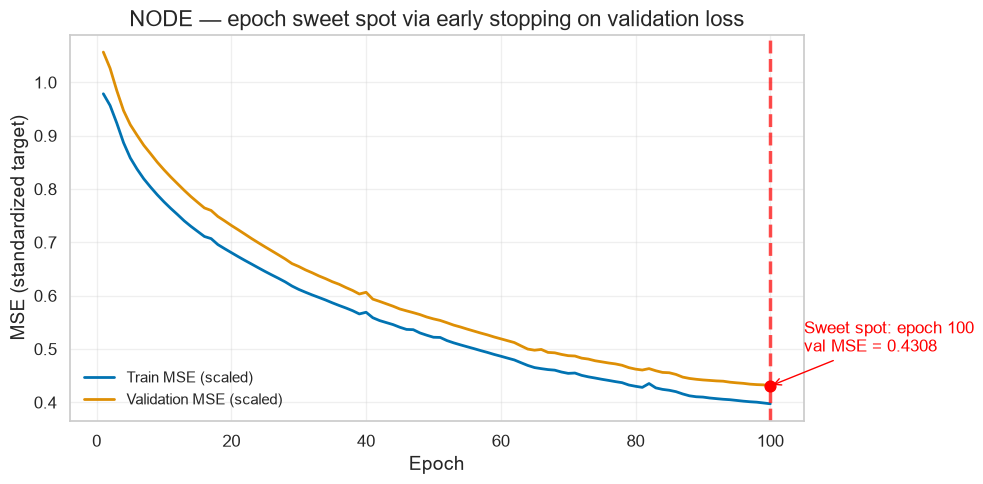

In [14]:
# Visualize the NODE epoch sweet spot: train vs validation loss curves
epochs_ran = range(1, len(node_history['train_loss']) + 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(epochs_ran, node_history['train_loss'], label='Train MSE (scaled)', lw=2)
ax.plot(epochs_ran, node_history['val_loss'], label='Validation MSE (scaled)', lw=2)

ax.axvline(node_best_epoch, color='red', ls='--', alpha=0.7)
ax.scatter([node_best_epoch], [node_best_val_loss], color='red', zorder=5, s=60)
ax.annotate(
    f'Sweet spot: epoch {node_best_epoch}\nval MSE = {node_best_val_loss:.4f}',
    xy=(node_best_epoch, node_best_val_loss),
    xytext=(node_best_epoch + 0.05 * len(node_history['val_loss']), node_best_val_loss * 1.15),
    arrowprops=dict(arrowstyle='->', color='red'),
    color='red',
)

ax.set_xlabel('Epoch')
ax.set_ylabel('MSE (standardized target)')
ax.set_title('NODE — epoch sweet spot via early stopping on validation loss')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Summary comparison
print("\n" + "="*80)
print("MODEL COMPARISON SUMMARY")
print("="*80)

summary_df = pd.DataFrame(metrics_results)
print(summary_df.to_string(index=False))

# Find best model for each metric
print("\n" + "="*80)
print("BEST MODELS BY METRIC")
print("="*80)

# Define metrics and their optimization direction (lower is better or higher is better)
metric_config = {
    'RMSE': 'min',
    'MAE': 'min',
    'MAPE': 'min',
    'MASE': 'min',
    'R²': 'max',
    'SMAPE': 'min'
}

best_models = {}

for metric, direction in metric_config.items():
    if metric in summary_df.columns:
        if direction == 'min':
            best_idx = summary_df[metric].idxmin()
            best_value = summary_df[metric].min()
        else:  # max
            best_idx = summary_df[metric].idxmax()
            best_value = summary_df[metric].max()

        best_model_name = summary_df.loc[best_idx, 'Model']
        best_models[metric] = {
            'model': best_model_name,
            'value': best_value
        }

        print(f"  {metric:8s}: {best_model_name:15s} ({best_value:.4f})")

# Overall best model (by RMSE as primary metric)
overall_best = best_models['RMSE']['model']
print(f"\n✓ Overall best model (by RMSE): {overall_best}")

print("\n✓ All models trained successfully!")